# JS09 Praktikum 3 PBL - Text Classification Sleep Wise

Notebook ini merupakan implementasi PBL menggunakan dataset *Sleep Health and Lifestyle*.

## 1. Tujuan

Mengubah atribut teks menjadi representasi TF-IDF dan mengklasifikasikan gangguan tidur.

## 2. Dataset dan Alur Praktikum

Dataset disimpan pada `Dataset/Sleep_health_and_lifestyle_dataset.csv`. Alur: **load -> cleaning -> feature engineering -> pemodelan -> evaluasi -> visualisasi**.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

plt.style.use("seaborn-v0_8-whitegrid")

csv_path = Path("../Dataset/Sleep_health_and_lifestyle_dataset.csv")
df = pd.read_csv(csv_path)
print("Ukuran dataset:", df.shape)
df.head()

Ukuran dataset: (374, 13)


,Person ID,Gender,Age,Occupation,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,BMI Category,Blood Pressure,Heart Rate,Daily Steps,Sleep Disorder
0,1,Male,27,Software Engineer,6.1,6,42,6,Overweight,126/83,77,4200,NaN
1,2,Male,28,Doctor,6.2,6,60,8,Normal,125/80,75,10000,NaN
2,3,Male,28,Doctor,6.2,6,60,8,Normal,125/80,75,10000,NaN
3,4,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea
4,5,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea


## 3. Eksplorasi dan Pembersihan Data

In [2]:
print("Informasi dataset:")
df.info()

print("\nNilai kosong:")
print(df.isna().sum())
print("\nDuplikasi:", df.duplicated().sum())

df = df.copy()
df["Sleep Disorder"] = df["Sleep Disorder"].fillna("None")

bp = df["Blood Pressure"].str.split("/", expand=True).astype(float)
df["Systolic BP"] = bp[0]
df["Diastolic BP"] = bp[1]
print("\nDistribusi Sleep Disorder:")
print(df["Sleep Disorder"].value_counts())

Informasi dataset:
<class 'pandas.DataFrame'>
RangeIndex: 374 entries, 0 to 373
Data columns (total 13 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Person ID                374 non-null    int64  
 1   Gender                   374 non-null    str    
 2   Age                      374 non-null    int64  
 3   Occupation               374 non-null    str    
 4   Sleep Duration           374 non-null    float64
 5   Quality of Sleep         374 non-null    int64  
 6   Physical Activity Level  374 non-null    int64  
 7   Stress Level             374 non-null    int64  
 8   BMI Category             374 non-null    str    
 9   Blood Pressure           374 non-null    str    
 10  Heart Rate               374 non-null    int64  
 11  Daily Steps              374 non-null    int64  
 12  Sleep Disorder           155 non-null    str    
dtypes: float64(1), int64(7), str(5)
memory usage: 38.1 KB

Nilai kosong:
Per

### Cek kualitas data dan ringkasan statistik

,count,mean,std,min,25%,50%,75%,max
Person ID,374.0,187.500000,108.108742,1.0,94.25,187.5,280.75,374.0
Age,374.0,42.184492,8.673133,27.0,35.25,43.0,50.00,59.0
Sleep Duration,374.0,7.132086,0.795657,5.8,6.40,7.2,7.80,8.5
Quality of Sleep,374.0,7.312834,1.196956,4.0,6.00,7.0,8.00,9.0
Physical Activity Level,374.0,59.171123,20.830804,30.0,45.00,60.0,75.00,90.0
Stress Level,374.0,5.385027,1.774526,3.0,4.00,5.0,7.00,8.0
Heart Rate,374.0,70.165775,4.135676,65.0,68.00,70.0,72.00,86.0
Daily Steps,374.0,6816.844920,1617.915679,3000.0,5600.00,7000.0,8000.00,10000.0
Systolic BP,374.0,128.553476,7.748118,115.0,125.00,130.0,135.00,142.0
Diastolic BP,374.0,84.649733,6.161611,75.0,80.00,85.0,90.00,95.0


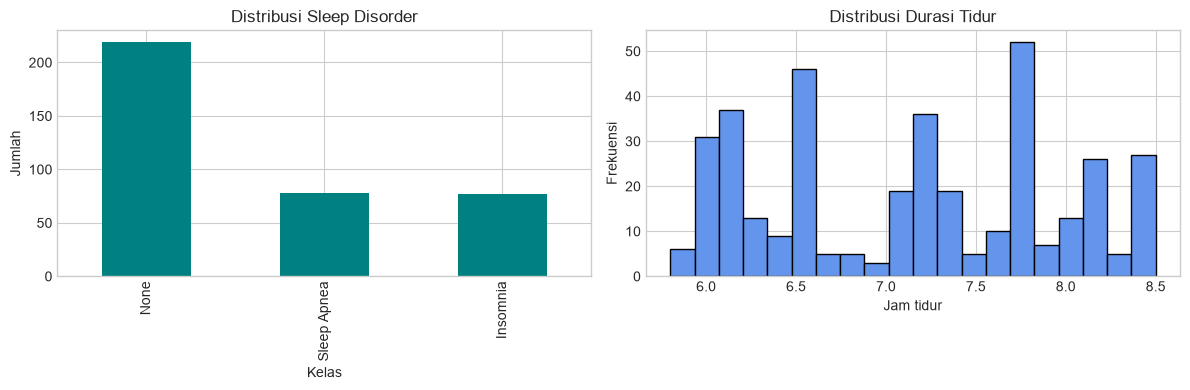

In [3]:
display(df.describe(include="number").T)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
df["Sleep Disorder"].value_counts().plot(kind="bar", ax=axes[0], color="teal")
axes[0].set_title("Distribusi Sleep Disorder")
axes[0].set_xlabel("Kelas")
axes[0].set_ylabel("Jumlah")

df["Sleep Duration"].hist(bins=20, ax=axes[1], color="cornflowerblue", edgecolor="black")
axes[1].set_title("Distribusi Durasi Tidur")
axes[1].set_xlabel("Jam tidur")
axes[1].set_ylabel("Frekuensi")
plt.tight_layout()
plt.show()

## 4. Pembentukan Teks dan Feature Engineering

In [4]:
df["Text Feature"] = (
    df["Gender"].fillna("") + " " +
    df["Occupation"].fillna("") + " " +
    df["BMI Category"].fillna("")
).str.lower()

X_text = df["Text Feature"]
y = df["Sleep Disorder"]
print(df[["Text Feature", "Sleep Disorder"]].head())

                        Text Feature Sleep Disorder
0  male software engineer overweight           None
1                 male doctor normal           None
2                 male doctor normal           None
3    male sales representative obese    Sleep Apnea
4    male sales representative obese    Sleep Apnea


## 5. Split dan Pelatihan TF-IDF

In [5]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

X_train, X_test, y_train, y_test = train_test_split(
    X_text, y, test_size=.2, random_state=42, stratify=y
)
model = Pipeline([
    ("tfidf", TfidfVectorizer(ngram_range=(1, 2))),
    ("classifier", LogisticRegression(max_iter=1000)),
])
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

## 6. Evaluasi dan Visualisasi

              precision    recall  f1-score   support

    Insomnia       0.86      0.80      0.83        15
        None       0.85      0.93      0.89        44
 Sleep Apnea       0.92      0.75      0.83        16

    accuracy                           0.87        75
   macro avg       0.88      0.83      0.85        75
weighted avg       0.87      0.87      0.86        75



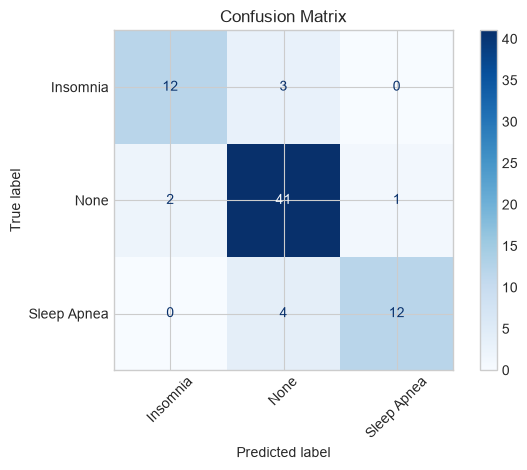

In [6]:
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

print(classification_report(y_test, y_pred, zero_division=0))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, cmap="Blues", xticks_rotation=45
)
plt.title("Confusion Matrix")
plt.tight_layout()
plt.show()

## 7. Kesimpulan

Catat parameter model terbaik, hasil evaluasi, serta hubungan temuan dengan kasus Sleep Wise.